# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


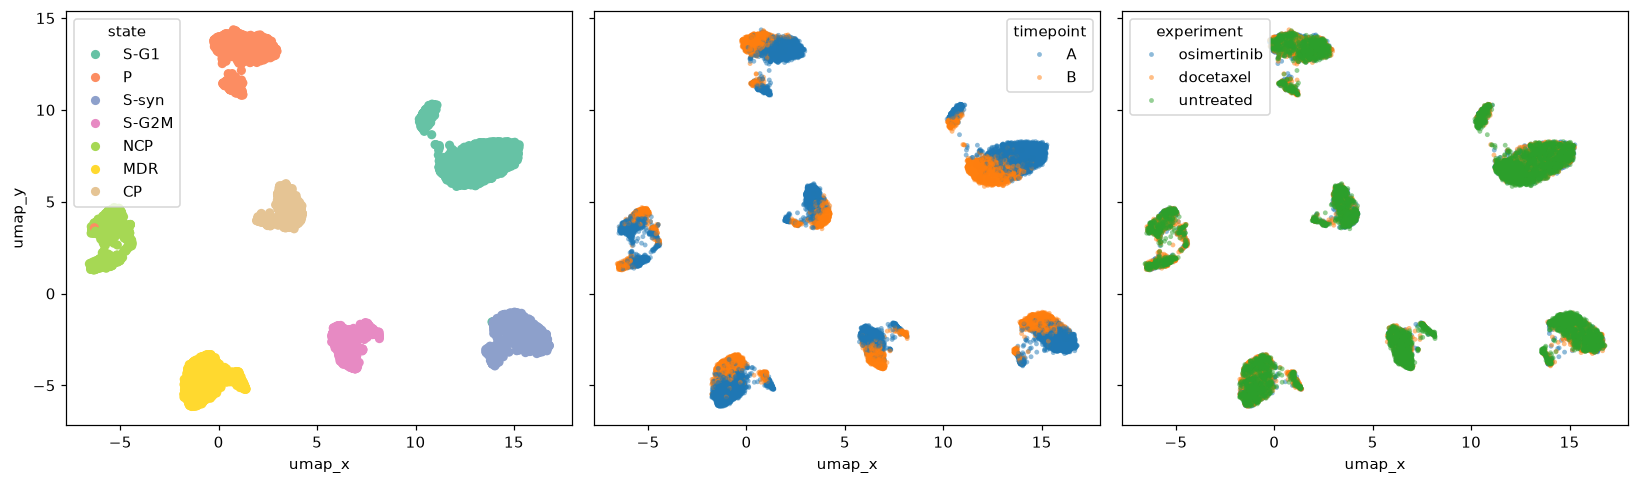

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

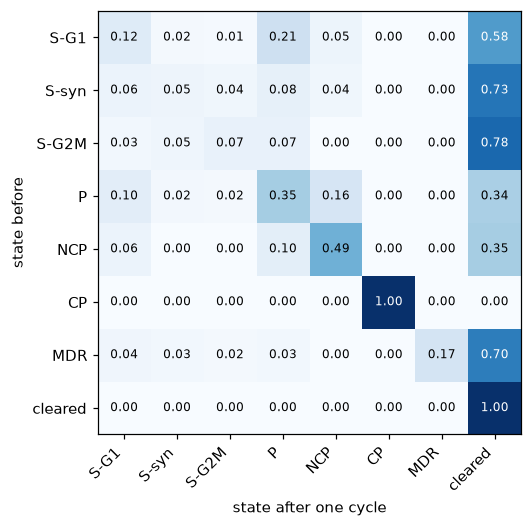

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

It appears that CP is also an absorbing state because it has the probability of 1 that CP goes to CP. This means that this type of cell is not responsive to osimertinib because there is no chance of it going to cleared. This could suggest that CP cells are resistant to the drug and the tumor is unable to be cleared if it contains these cells.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

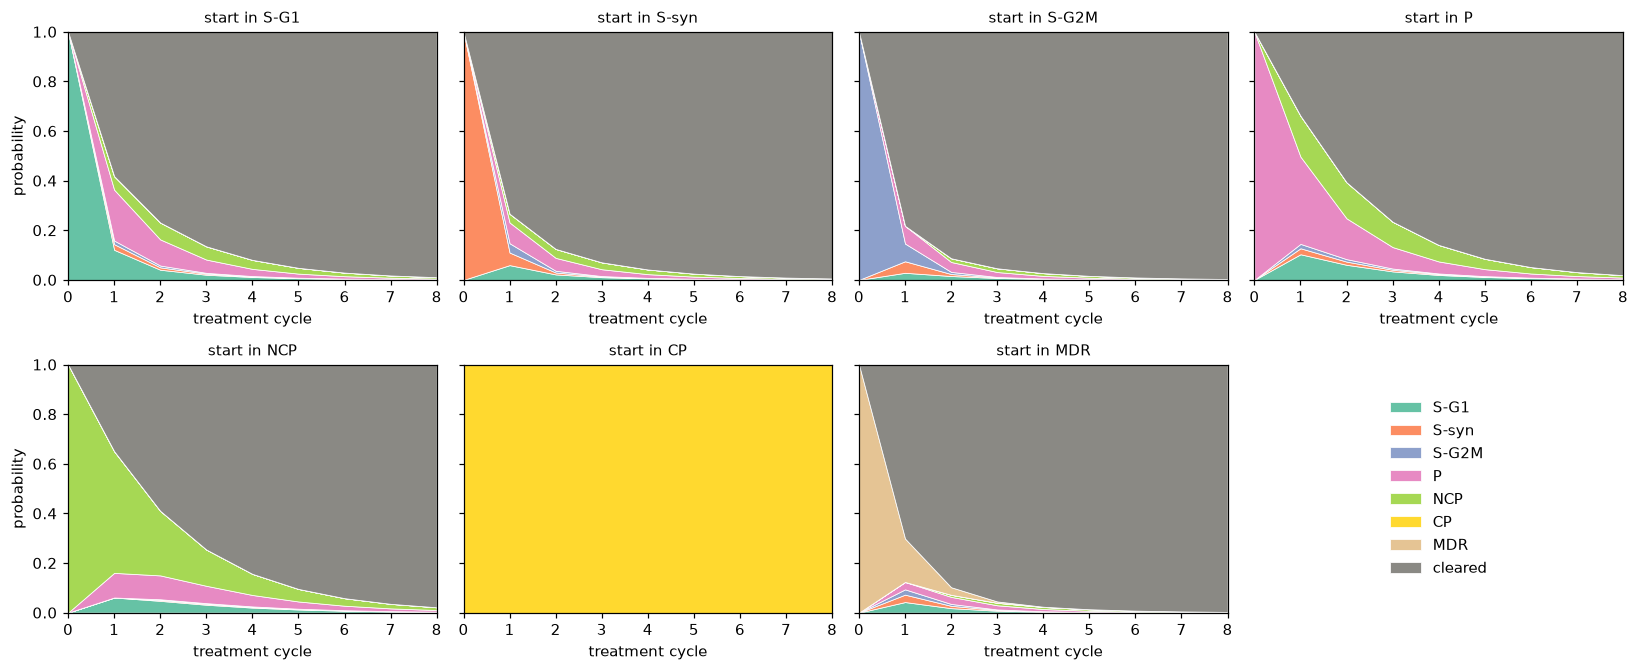

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [16]:
# Evolve a single-state tumor under osimertinib for many cycles and summarize survival
P_osi_np = P_hat.to_numpy()
cleared = OUTCOMES.index("cleared")
N_LONG = 200                                      # long enough to see each state's final fate

rows = []
for s in STATES:
    traj = evolve(basis(s, P_hat), P_osi_np, N_LONG)
    alive = 1 - traj[:, cleared]                  # fraction of cells not yet cleared at each cycle
    rows.append({
        "start": s,
        "alive after 3 cycles": alive[3],
        "alive after 8 cycles": alive[8],
        f"alive after {N_LONG} cycles": alive[N_LONG],
        "eliminated?": alive[N_LONG] < 1e-6,
        "cycles until <1% alive": int(np.argmax(alive < 0.01)) if (alive < 0.01).any() else np.nan,
        # expected number of cycles a starting cell survives = sum_t P(alive at t); capped at N_LONG
        "expected cycles survived": alive[1:].sum(),
    })
survival = pd.DataFrame(rows).set_index("start")
display(survival.round(3))

clearable = survival[survival["eliminated?"]]
print("Eliminated by osimertinib:", list(clearable.index))
print("Survive osimertinib:      ", list(survival.index[~survival["eliminated?"]]))
print("Clearable state that lasts longest:", clearable["expected cycles survived"].idxmax())
print("State that sticks around the most cycles:", survival["expected cycles survived"].idxmax())
print("Highest fraction alive after 3 cycles:", survival["alive after 3 cycles"].idxmax())

,alive after 3 cycles,alive after 8 cycles,alive after 200 cycles,eliminated?,cycles until <1% alive,expected cycles survived
start,,,,,,
S-G1,0.135,0.011,0.0,True,9.0,0.988
S-syn,0.071,0.006,0.0,True,7.0,0.568
S-G2M,0.047,0.004,0.0,True,6.0,0.420
P,0.234,0.019,0.0,True,10.0,1.647
NCP,0.254,0.022,0.0,True,10.0,1.716
CP,1.000,1.000,1.0,False,NaN,200.000
MDR,0.045,0.003,0.0,True,6.0,0.504


Eliminated by osimertinib: ['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'MDR']
Survive osimertinib:       ['CP']
Clearable state that lasts longest: NCP
State that sticks around the most cycles: CP
Highest fraction alive after 3 cycles: CP


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

pi_mix: {'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


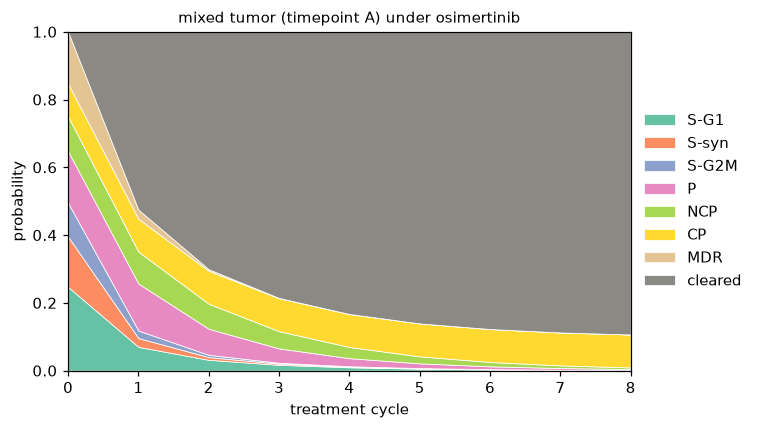

In [17]:
# Starting vector: fraction of timepoint-A cells in each state, pooled across all three experiments
at_A_all = cells[cells["timepoint"] == "A"]
pi_mix = (at_A_all["state"].value_counts(normalize=True)
            .reindex(OUTCOMES, fill_value=0)       # "cleared" gets 0: no cell starts dead
            .to_numpy())
assert np.isclose(pi_mix.sum(), 1)
print("pi_mix:", dict(zip(OUTCOMES, pi_mix.round(3))))

# evolve pi_mix under osimertinib and plot the results
traj_mix = evolve(pi_mix, P_hat.to_numpy(), N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(traj_mix, ax, "mixed tumor (timepoint A) under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

The remaining states are cleared and CP. The CP cells are not ever going to be cleared from this drug. The transistion matrix shows that if a cell is CP it will continue to be CP since it has a probability of 1.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [21]:
def transition_matrix(experiment):
    '''Estimate the 8x8 one-cycle transition matrix (with the absorbing "cleared" row) for one experiment.'''
    exp = cells[cells["experiment"] == experiment]
    A = exp[exp.timepoint == "A"][["lineage_tag", "state"]]
    B = exp[exp.timepoint == "B"][["lineage_tag", "state"]]
    pr = pd.merge(A, B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pr["state_B"] = pr["state_B"].fillna("cleared")
    cnt = (pd.crosstab(pr.state_A, pr.state_B)
             .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = cnt.div(cnt.sum(axis=1), axis=0)
    P.loc["cleared"] = [1 if c == "cleared" else 0 for c in OUTCOMES]
    assert np.allclose(P.sum(axis=1), 1), f"{experiment}: every row should sum to 1."
    return P

P_doc_df = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")

# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()
P_doc = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

# absorbing states: a cell in state i stays in i with probability ~1
for name, P in [("osimertinib", P_osi), ("docetaxel", P_doc), ("drug holiday", P_holiday)]:
    absorbing = [s for i, s in enumerate(OUTCOMES) if P[i, i] > 0.99]
    print(f"{name:13s} absorbing states: {absorbing}")

# side-by-side numbers: how docetaxel and the holiday differ from osimertinib
print("\nP(cleared) in one cycle, by starting state:")
display(pd.DataFrame({"osimertinib": P_hat["cleared"],
                      "docetaxel": P_doc_df["cleared"],
                      "drug holiday": P_holiday_df["cleared"]}).loc[STATES].round(3))
print("P(stay in the same state) in one cycle:")
display(pd.DataFrame({"osimertinib": np.diag(P_osi),
                      "docetaxel": np.diag(P_doc),
                      "drug holiday": np.diag(P_holiday)}, index=OUTCOMES).loc[STATES].round(3))

osimertinib   absorbing states: ['CP', 'cleared']
docetaxel     absorbing states: ['MDR', 'cleared']
drug holiday  absorbing states: ['cleared']

P(cleared) in one cycle, by starting state:


,osimertinib,docetaxel,drug holiday
state_A,,,
S-G1,0.582,0.376,0.050
S-syn,0.733,0.620,0.048
S-G2M,0.782,0.870,0.060
P,0.338,0.352,0.061
NCP,0.349,0.370,0.041
CP,0.000,0.724,0.052
MDR,0.701,0.000,0.051


P(stay in the same state) in one cycle:


,osimertinib,docetaxel,drug holiday
S-G1,0.121,0.293,0.412
S-syn,0.051,0.111,0.342
S-G2M,0.071,0.035,0.269
P,0.352,0.409,0.324
NCP,0.490,0.436,0.478
CP,1.000,0.100,0.820
MDR,0.175,1.000,0.542


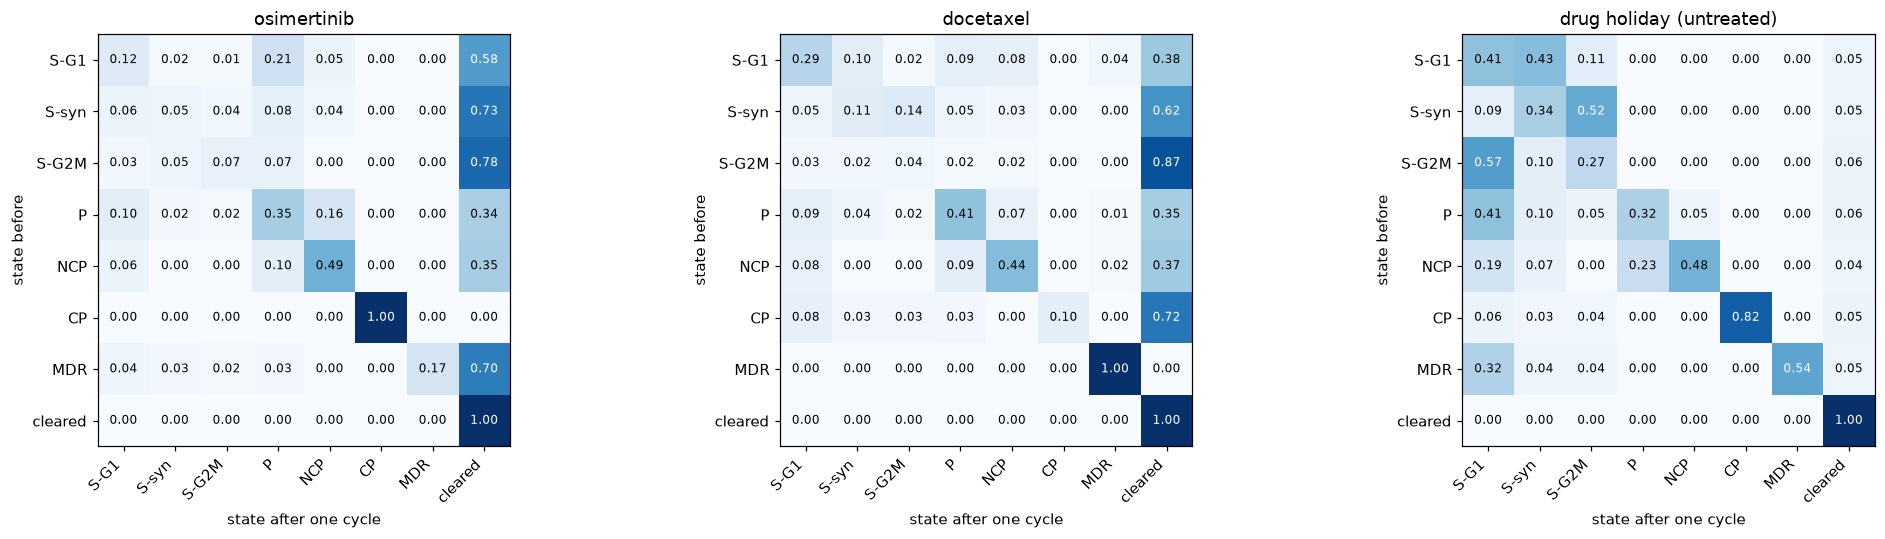

In [22]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
show_matrix(P_hat, "osimertinib", ax=axes[0])
show_matrix(P_doc_df, "docetaxel", ax=axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", ax=axes[2])
plt.tight_layout()
plt.show()

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


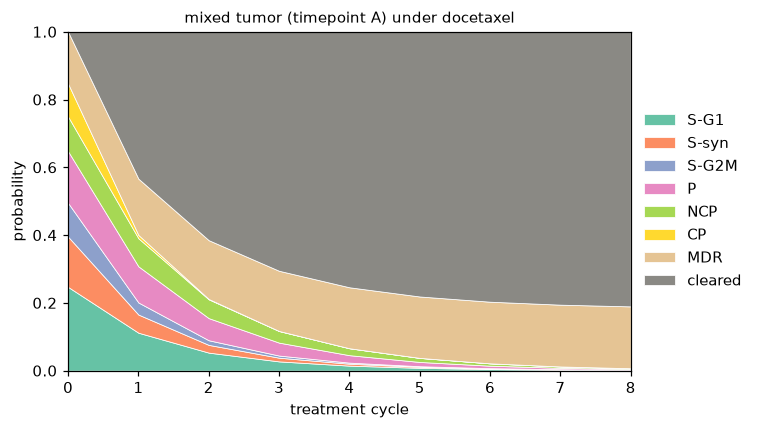

fraction alive after 8 cycles: docetaxel 0.190, osimertinib 0.107
composition of surviving cells (docetaxel): {'S-G1': np.float64(0.008), 'S-syn': np.float64(0.003), 'S-G2M': np.float64(0.002), 'P': np.float64(0.012), 'NCP': np.float64(0.012), 'CP': np.float64(0.0), 'MDR': np.float64(0.963)}


In [23]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
plot_trajectory(traj_doc, ax, "mixed tumor (timepoint A) under docetaxel")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

# compare the end of 8 cycles with osimertinib
traj_osi = evolve(pi_mix, P_osi, N_CYCLES)
alive_doc, alive_osi = traj_doc[-1, :-1], traj_osi[-1, :-1]
print(f"fraction alive after {N_CYCLES} cycles: docetaxel {alive_doc.sum():.3f}, osimertinib {alive_osi.sum():.3f}")
print("composition of surviving cells (docetaxel):",
      dict(zip(STATES, (alive_doc / alive_doc.sum()).round(3))))

1. For the docetaxel the transition matrix shows that MDR is the cell type that is an absorbing state. It has the probabilty of 1 for staying as the same type.

2. The mixed tumor under Docetaxel shows that the cells that were not cleared became MDR and remained MDR.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

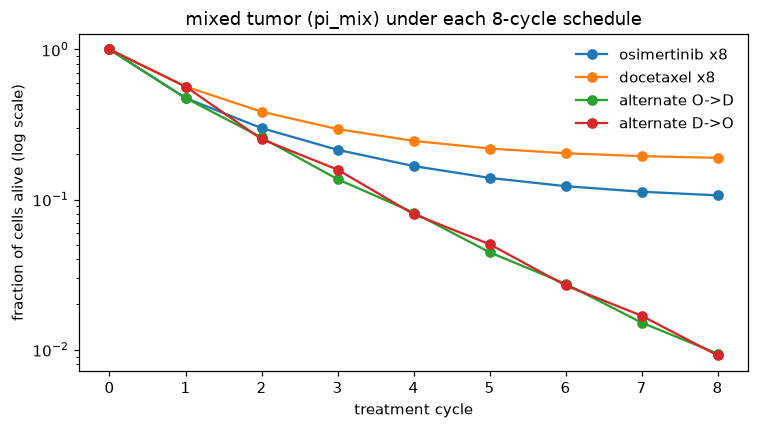

,alive after 8,S-G1,S-syn,S-G2M,P,NCP,CP,MDR
osimertinib x8,0.1066,0.0013,0.0002,0.0001,0.0030,0.0048,0.0972,0.0000
docetaxel x8,0.1896,0.0015,0.0006,0.0003,0.0024,0.0023,0.0000,0.1826
alternate O->D,0.0094,0.0016,0.0005,0.0003,0.0030,0.0033,0.0000,0.0007
alternate D->O,0.0092,0.0014,0.0003,0.0002,0.0031,0.0038,0.0000,0.0003


In [24]:
# A schedule is a string with one letter per cycle: O = osimertinib, D = docetaxel, H = drug holiday.
# pi @ P_osi @ P_doc means "osimertinib first, then docetaxel", so "OD"*4 is one OD pair repeated 4 times = 8 rounds.
DRUGS = {"O": P_osi, "D": P_doc, "H": P_holiday}
CLEARED = OUTCOMES.index("cleared")

def run_schedule(pi0, schedule):
    '''Return the (len(schedule) + 1, 8) trajectory of pi0 under the schedule.'''
    traj = [np.asarray(pi0, dtype=float)]
    for letter in schedule:
        traj.append(traj[-1] @ DRUGS[letter])
    return np.array(traj)

def frac_alive(traj):
    '''Fraction of cells not cleared at each cycle.'''
    return 1 - traj[:, CLEARED]

def rounds_to_clear(traj, threshold=0.01):
    '''First cycle at which fewer than `threshold` of cells are alive (NaN if never within the schedule).'''
    hit = np.flatnonzero(frac_alive(traj) < threshold)
    return int(hit[0]) if hit.size else np.nan

schedules = {
    "osimertinib x8": "O" * 8,
    "docetaxel x8":   "D" * 8,
    "alternate O->D": "OD" * 4,
    "alternate D->O": "DO" * 4,
}

final = {}
fig, ax = plt.subplots(figsize=(7, 4))
for name, sch in schedules.items():
    traj = run_schedule(pi_mix, sch)
    final[name] = traj[-1]
    ax.plot(range(len(sch) + 1), frac_alive(traj), marker="o", label=name)
ax.set_yscale("log")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("fraction of cells alive (log scale)")
ax.set_title("mixed tumor (pi_mix) under each 8-cycle schedule")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# final state distribution after 8 cycles (each row sums to 1 with "cleared")
summary = pd.DataFrame(final, index=OUTCOMES).T
summary.insert(0, "alive after 8", 1 - summary["cleared"])
summary.drop(columns="cleared").round(4)

In [ ]:
# A holiday kills few cells, but it lets resistant cells (CP, MDR) switch back to sensitive states.
# Compare each all-drug schedule to an 8-cycle schedule with holidays mixed in.
holiday_tests = {
    "all CP":  (basis("CP", P_hat),  ["O" * 8, "HO" * 4, "D" * 8, "HD" * 4]),
    "all MDR": (basis("MDR", P_hat), ["D" * 8, "HD" * 4, "O" * 8, "HO" * 4]),
    "pi_mix":  (pi_mix,              ["O" * 8, "HO" * 4, "D" * 8, "HD" * 4, "OD" * 4, "OHDH" * 2]),
}
rows = []
for start, (pi0, schs) in holiday_tests.items():
    for sch in schs:
        traj = run_schedule(pi0, sch)
        rows.append({"start": start, "schedule": sch,
                     "holiday cycles": sch.count("H"),
                     "alive after 8": frac_alive(traj)[-1],
                     "rounds to <1% alive": rounds_to_clear(traj)})
pd.DataFrame(rows).set_index(["start", "schedule"]).round(4)

holiday cycles  alive after 8  rounds to <1% alive
start   schedule                                                    
all CP  OOOOOOOO               0         1.0000                  NaN
        HOHOHOHO               4         0.4948                  NaN
        DDDDDDDD               0         0.0101                  NaN
        HDHDHDHD               4         0.0225                  NaN
all MDR DDDDDDDD               0         1.0000                  NaN
        HDHDHDHD               4         0.2018                  NaN
        OOOOOOOO               0         0.0029                  6.0
        HOHOHOHO               4         0.0199                  NaN
pi_mix  OOOOOOOO               0         0.1066                  NaN
        HOHOHOHO               4         0.0728                  NaN
        DDDDDDDD               0         0.1896                  NaN
        HDHDHDHD               4         0.0704                  NaN
        ODODODOD               0         0.0094                  8.0
        OHDHOHDH               4         0.0421                  NaN

In [ ]:
starts = {f"all {s}": basis(s, P_hat) for s in STATES}
starts.update({
    "pi_mix":             pi_mix,
    "90% S-G1 + 10% CP":  0.9 * basis("S-G1", P_hat) + 0.1 * basis("CP", P_hat),
    "90% S-G1 + 10% MDR": 0.9 * basis("S-G1", P_hat) + 0.1 * basis("MDR", P_hat),
    "50% CP + 50% MDR":   0.5 * basis("CP", P_hat) + 0.5 * basis("MDR", P_hat),
})
plans = {"O x8": "O" * 8, "D x8": "D" * 8, "OD x4": "OD" * 4, "DO x4": "DO" * 4,
         "OOOODDDD": "O" * 4 + "D" * 4, "DDDDOOOO": "D" * 4 + "O" * 4, "HOHD x2": "HOHD" * 2}

alive8 = pd.DataFrame({p: {s: frac_alive(run_schedule(pi0, sch))[-1] for s, pi0 in starts.items()}
                       for p, sch in plans.items()})
rounds = pd.DataFrame({p: {s: rounds_to_clear(run_schedule(pi0, sch)) for s, pi0 in starts.items()}
                       for p, sch in plans.items()})
print("fraction of cells alive after 8 cycles:")
display(alive8.round(4))
print("rounds until <1% of cells are alive (NaN = not reached within 8 cycles):")
display(rounds)

# best plan per tumor: fewest rounds to reach <1% alive; ties (or plans that never get there) broken by fewest alive at 8
rows = []
for s in starts:
    ranked = pd.DataFrame({"rounds": rounds.loc[s].fillna(np.inf), "alive": alive8.loc[s]}).sort_values(["rounds", "alive"])
    p = ranked.index[0]
    rows.append({"start": s, "best plan": p,
                 "rounds to <1% alive": rounds.loc[s, p], "alive after 8": alive8.loc[s, p]})
print("best plan for each starting tumor:")
pd.DataFrame(rows).set_index("start").round(4)

fraction of cells alive after 8 cycles:


,O x8,D x8,OD x4,DO x4,OOOODDDD,DDDDOOOO,HOHD x2
all S-G1,0.0108,0.0727,0.0099,0.0109,0.0130,0.0125,0.0285
all S-syn,0.0056,0.0124,0.0051,0.0047,0.0068,0.0046,0.0206
all S-G2M,0.0036,0.0059,0.0032,0.0021,0.0043,0.0021,0.0300
all P,0.0190,0.0545,0.0170,0.0154,0.0228,0.0155,0.0465
all NCP,0.0216,0.0681,0.0190,0.0172,0.0258,0.0173,0.0644
all CP,1.0000,0.0101,0.0064,0.0036,0.0346,0.0034,0.0466
all MDR,0.0029,1.0000,0.0048,0.0073,0.0045,0.0237,0.0324
pi_mix,0.1066,0.1896,0.0094,0.0092,0.0148,0.0121,0.0363
90% S-G1 + 10% CP,0.1097,0.0664,0.0096,0.0101,0.0152,0.0116,0.0303
90% S-G1 + 10% MDR,0.0100,0.1654,0.0094,0.0105,0.0121,0.0137,0.0289


rounds until <1% of cells are alive (NaN = not reached within 8 cycles):


,O x8,D x8,OD x4,DO x4,OOOODDDD,DDDDOOOO,HOHD x2
all S-G1,NaN,NaN,8.0,NaN,NaN,NaN,NaN
all S-syn,7.0,NaN,7.0,7.0,8.0,7.0,NaN
all S-G2M,6.0,6.0,6.0,6.0,7.0,6.0,NaN
all P,NaN,NaN,NaN,NaN,NaN,NaN,NaN
all NCP,NaN,NaN,NaN,NaN,NaN,NaN,NaN
all CP,NaN,NaN,8.0,7.0,NaN,6.0,NaN
all MDR,6.0,NaN,7.0,8.0,6.0,NaN,NaN
pi_mix,NaN,NaN,8.0,8.0,NaN,NaN,NaN
90% S-G1 + 10% CP,NaN,NaN,8.0,NaN,NaN,NaN,NaN
90% S-G1 + 10% MDR,NaN,NaN,8.0,NaN,NaN,NaN,NaN


best plan for each starting tumor:


,best plan,rounds to <1% alive,alive after 8
start,,,
all S-G1,OD x4,8.0,0.0099
all S-syn,DDDDOOOO,7.0,0.0046
all S-G2M,DO x4,6.0,0.0021
all P,DO x4,NaN,0.0154
all NCP,DO x4,NaN,0.0172
all CP,DDDDOOOO,6.0,0.0034
all MDR,O x8,6.0,0.0029
pi_mix,DO x4,8.0,0.0092
90% S-G1 + 10% CP,OD x4,8.0,0.0096


1. The results from building the alternating schedule versus just one drug are that the alternating schedule kills all the cells, while the single drug ones still have some cells remaining. 

2. It does not appear to matter which drug is the starting one for the alternating scheudle. Both lines follow similar trends. 

3. The holidays help when the tumor has the cells that are resistant to the current version of drugs. The CP and MDR cells can possibly switch back to other kinds during a holiday, which could then be treated by the drugs.

4. The table above shows the exact best treatment plans for 11 starts. For the tumors that are either single cells or mostly made of of the resistant cells (CP and MDR), the best treatments are to use the drug they are not resistant to. FOr the mixed tumors with non reisistant cells, an alternating cycle is best and helps to avoid cells turning to only resistant. 

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [27]:
rng = np.random.default_rng(100)

In [28]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [29]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

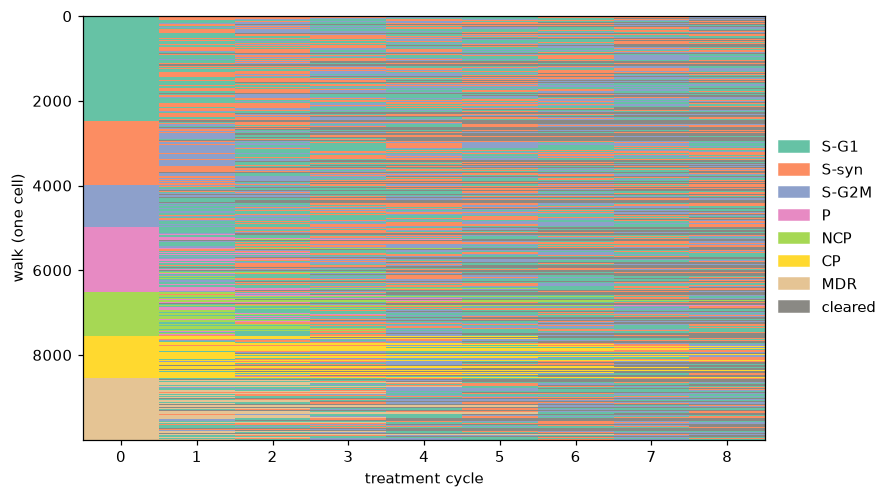

In [33]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [34]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

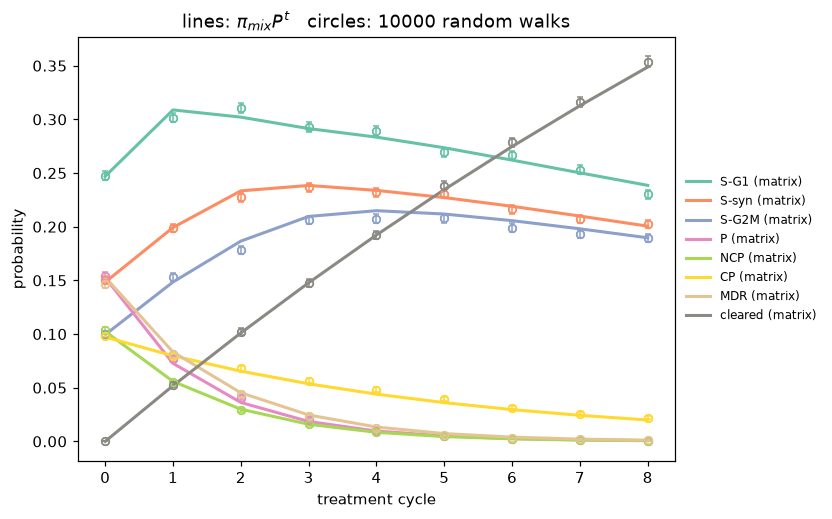

In [35]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

The circles are much closer to the lines and have very small error bars. The standard error and noise shrinks when the population grows because of the law of large numbers, the experimental probabilites match the theroetical probabilites much closer as the population grows.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [36]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

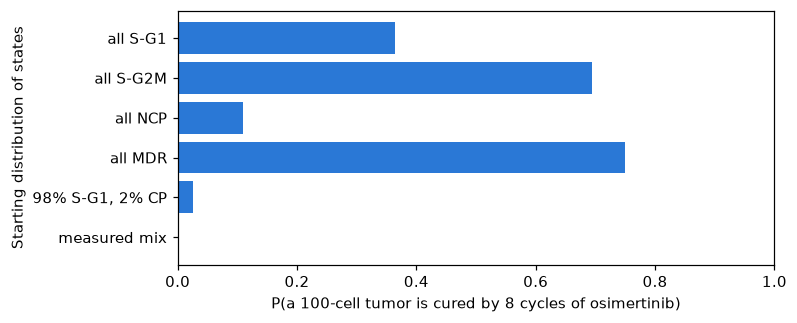

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [ ]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

The results show that the tumors that are mostly or all MDR are not effectively cured by docetaxel. Almost none of the tumors are cured at all over the 8 cycles, likely because the cells turned into MDR over the course of the treatment and the drug cannot kill that. The only starting tumor that was cured was S-G2M.

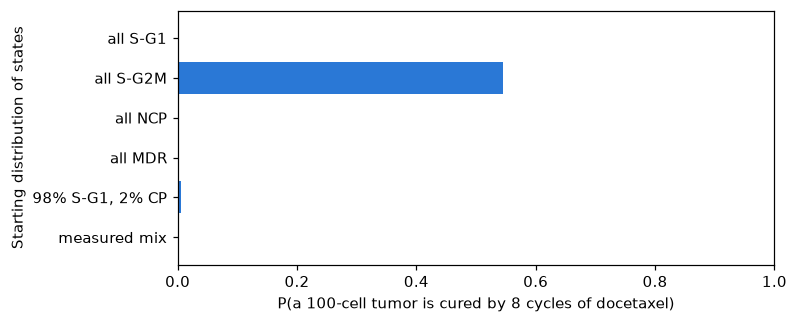

osimertinib                       \
                   P(cured) mean surviving cells   
start                                              
all S-G1              0.365                1.025   
all S-G2M             0.695                0.345   
all NCP               0.110                2.140   
all MDR               0.750                0.275   
98% S-G1, 2% CP       0.025                3.190   
measured mix          0.000               10.685   

                                               docetaxel                       \
                share of survivors that are CP  P(cured) mean surviving cells   
start                                                                           
all S-G1                                 0.000     0.000                7.805   
all S-G2M                                0.000     0.545                0.610   
all NCP                                  0.000     0.000                6.690   
all MDR                                  0.000     0.000              100.000   
98% S-G1, 2% CP                          0.638     0.005                6.985   
measured mix                             0.918     0.000               18.955   

                                                                                
                share of survivors that are MDR share of survivors that are CP  
start                                                                           
all S-G1                                  0.863                            0.0  
all S-G2M                                 0.631                            0.0  
all NCP                                   0.800                            0.0  
all MDR                                   1.000                            0.0  
98% S-G1, 2% CP                           0.866                            0.0  
measured mix                              0.964                            0.0

In [38]:
# Same simulation as above, but 8 cycles of docetaxel. 
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are MDR":
                     (finals == OUTCOMES.index("MDR")).sum() / max(alive.sum(), 1),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results_doc = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results_doc.index[::-1], results_doc["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()

# side by side with the osimertinib results from the cell above
pd.concat({"osimertinib": results, "docetaxel": results_doc}, axis=1).round(3)

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [40]:
PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

# write a function that runs 1000 random walks and saves them
def tumor_walks(pi0, schedule, n_cells=1000, rng=rng):
    '''Run n_cells random walks at once (one tumor). Starting states are drawn from pi0;
    schedule is a list with one transition matrix per cycle.
    Returns an (n_cells, len(schedule) + 1) array of state indices.'''
    state = rng.choice(len(pi0), size=n_cells, p=pi0)
    path = [state]
    for P in schedule:
        cdf = np.cumsum(P, axis=1)[state]                 # each cell's row CDF
        u = rng.random(n_cells)[:, None]                  # inverse-CDF: first state whose CDF exceeds U
        state = np.minimum((u > cdf).sum(axis=1), len(OUTCOMES) - 1)
        path.append(state)
    return np.array(path).T

# go through each random walk and find the longest run of consecutive cycles spent in P or NCP
# (switching between P and NCP still counts as staying a persister)
def longest_persister_run(walks):
    in_persister = np.isin(walks, PERSISTER)
    run = np.zeros(len(walks), dtype=int)
    longest = np.zeros(len(walks), dtype=int)
    for t in range(walks.shape[1]):
        run = np.where(in_persister[:, t], run + 1, 0)
        longest = np.maximum(longest, run)
    return longest

# count up cells that stayed in a persister state for 3+ consecutive cycles, out of total cells
def frac_permanently_resistant(walks, min_cycles=3):
    return np.mean(longest_persister_run(walks) >= min_cycles)

# repeat for all tumors: 100 tumors of 1000 cells, starting from the measured mix, 8 cycles of osimertinib
N_PR_TUMORS, N_PR_CELLS, N_PR_CYCLES = 100, 1000, 8
pr_osi = np.array([frac_permanently_resistant(tumor_walks(pi_mix, [P_osi] * N_PR_CYCLES, N_PR_CELLS))
                   for _ in range(N_PR_TUMORS)])

# report mean +/- SEM for osimertinib
mean_pr = pr_osi.mean()
sem_pr = pr_osi.std(ddof=1) / np.sqrt(N_PR_TUMORS)
print(f"osimertinib x{N_PR_CYCLES}: fraction of cells permanently resistant = {mean_pr:.4f} +/- {sem_pr:.4f} (mean +/- SEM)")

# compare to 10% threshold using a 95% CI and a one-sample t-test
ci = (mean_pr - 1.96 * sem_pr, mean_pr + 1.96 * sem_pr)
t_stat = (mean_pr - 0.10) / sem_pr
print(f"95% CI: ({ci[0]:.4f}, {ci[1]:.4f})")
print(f"one-sample t vs 0.10: t = {t_stat:.2f} (|t| > 1.98 means significantly different at alpha = 0.05, df = {N_PR_TUMORS - 1})")
print("CI is entirely", "above" if ci[0] > 0.10 else "below" if ci[1] < 0.10 else "overlapping", "the 10% threshold")
print(f"tumors with > 10% permanently resistant cells: {np.mean(pr_osi > 0.10):.0%}")

osimertinib x8: fraction of cells permanently resistant = 0.1166 +/- 0.0010 (mean +/- SEM)
95% CI: (0.1148, 0.1185)
one-sample t vs 0.10: t = 17.26 (|t| > 1.98 means significantly different at alpha = 0.05, df = 99)
CI is entirely above the 10% threshold
tumors with > 10% permanently resistant cells: 97%


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

In [41]:
# Percentage of tumors with > 10% permanently resistant cells, by treatment and number of cycles
def make_schedule(plan, n_cycles):
    '''plan is a repeating pattern of matrices, e.g. [P_osi, P_doc]; trimmed to n_cycles.'''
    return [plan[i % len(plan)] for i in range(n_cycles)]

treatments = {
    "osimertinib alone":         [P_osi],
    "docetaxel alone":           [P_doc],
    "alternating OD":            [P_osi, P_doc],
    "docetaxel + drug holiday":  [P_doc, P_holiday],
}
cycle_counts = [4, 8, 12, 16]

pct_over_10 = pd.DataFrame(index=treatments, columns=cycle_counts, dtype=float)
mean_frac = pd.DataFrame(index=treatments, columns=cycle_counts, dtype=float)
for name, plan in treatments.items():
    for n in cycle_counts:
        fr = np.array([frac_permanently_resistant(tumor_walks(pi_mix, make_schedule(plan, n), N_PR_CELLS))
                       for _ in range(N_PR_TUMORS)])
        pct_over_10.loc[name, n] = 100 * np.mean(fr > 0.10)
        mean_frac.loc[name, n] = fr.mean()

pct_over_10.columns.name = mean_frac.columns.name = "cycles"
print("% of tumors with > 10% permanently resistant cells:")
display(pct_over_10.round(1))
print("mean fraction of permanently resistant cells per tumor:")
display(mean_frac.round(4))

% of tumors with > 10% permanently resistant cells:


cycles,4,8,12,16
osimertinib alone,86.0,97.0,93.0,94.0
docetaxel alone,2.0,15.0,12.0,16.0
alternating OD,47.0,71.0,75.0,80.0
docetaxel + drug holiday,5.0,39.0,60.0,65.0


mean fraction of permanently resistant cells per tumor:


cycles,4,8,12,16
osimertinib alone,0.1113,0.1165,0.1137,0.1172
docetaxel alone,0.0843,0.0910,0.0908,0.0914
alternating OD,0.0998,0.1054,0.1063,0.1080
docetaxel + drug holiday,0.0822,0.0979,0.1035,0.1040


Osimertinib alone
- this drug produces the most permanently reisistent cells. Aound 94-97% of the tumors pass the 10% cutoff by 8 cycles. The S cells are cleared quickly but the surviving cells become P and NCP with high probabilites. 

Doxetaxel alone
- This methid has the best results for avoiding high resistant cell amounts. It sits 12-16% of tumors over 10% after 8 cycles. Cells do not become P or NCP at the same high rate as osimertinib.

Alternating OD
- This is better than Osimertinib alone but because half the cycles are still just that drug, there is a high amount of reisistant cell build up that increases as the cycle number increases.

Doxetaxel with drug holiday
- This option starts with a low percentage but as the number of cycles rise, the percentage of tumors with large numbers of resistant cells rises dramatically. While the other options level off slighlty after 4-8 cycles, this ooptionappears to continue to rise.